## Notebook 06: Comprehensive Model Evaluation & Comparison

---

### 1. Architectural Role & Project Context
Rigorous validation in machine learning requires evaluating all candidate models under identical, independent test conditions. This notebook performs a head-to-head empirical evaluation across three paradigms:
1. **Rule-Based Heuristic Baseline**: Standard disaster management operating procedures.
2. **Random Forest Classifier**: Ensemble bagging with variance reduction.
3. **XGBoost Classifier**: Gradient-boosted decision trees with regularized learning.

All models are evaluated on the identical 1,000 held-out test scenarios (`data/processed/test_scenarios.csv`).

---

### 2. Linked Source Scripts (`src/component04_ml/`)
- **`src/component04_ml/evaluation.py`**:
  - `evaluate_all_models(test_df, preprocessor, rf_model, xgb_model, rule_prioritizer, artifacts_dir, ...)`: Computes multi-class metrics (Accuracy, Macro/Weighted Precision, Recall, F1), per-class breakdowns, confusion matrices, and comparison bar charts.
- **`src/component04_ml/rule_baseline.py`**:
  - `RuleBasedPrioritizer`: Evaluated side-by-side on test scenarios.
- **`src/component04_ml/preprocessing.py`**:
  - `DecisionDataPreprocessor`: Transforms test scenarios using frozen training parameters.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

root_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

from src.component04_ml.evaluation import evaluate_all_models

test_path = root_dir / "data" / "processed" / "test_scenarios.csv"
models_dir = root_dir / "models"
artifacts_dir = root_dir / "artifacts"


### Section 1: Execute Comprehensive Evaluation Suite
**Source Module:** `src/component04_ml/evaluation.py` -> `evaluate_all_models()`

#### Evaluation Protocol:
- Computes multi-class metrics across all 4 classes: P1 (Critical), P2 (High), P3 (Moderate), P4 (Low).
- Generates side-by-side Confusion Matrices saved to `artifacts/figures/confusion_matrices_comparison.png`.
- Produces comparative Macro F1 visualizations saved to `artifacts/figures/model_comparison_f1.png`.
- Logs structured JSON metrics to `artifacts/metrics/model_comparison_metrics.json`.


In [2]:
eval_results = evaluate_all_models(
    test_data_path=test_path,
    models_dir=models_dir,
    output_dir=artifacts_dir
)


### Section 2: Comparative Evaluation Summary Table
Here we examine the comparative performance matrix across all candidate architectures on the independent 1,000-scenario test set:
- **Rule Baseline**: Transparent but constrained by linear weighting and fixed threshold boundaries.
- **Random Forest**: Strong non-linear modeling, robust against noisy sensor inputs.
- **XGBoost**: Superior multi-class discrimination and calibration, particularly on edge-case interactions between telemetry latency and population exposure.


In [3]:
df_comp = eval_results["summary_df"]
print("Model Comparison Summary (Held-out Test Set, N=1,000):")
df_comp


Model Comparison Summary (Held-out Test Set, N=1,000):


,Model,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Critical P1 Recall
0,Rule-Based Baseline,0.560,0.5585,0.5414,0.6772,0.6054,0.3896
1,Random Forest Classifier,0.930,0.9124,0.9297,0.9281,0.8987,0.8312
2,XGBoost Classifier,0.956,0.9451,0.9559,0.9525,0.9382,0.8831


### Section 3: Display Confusion Matrices & Performance Charts
Displays the generated comparison figures:
- **Confusion Matrices**: Highlights safety-critical errors. Critical requirement: zero P1 scenarios misclassified as P4 (dangerous under-response).
- **Macro F1 Comparison Bar Chart**: Visually summarizes the progression from heuristic baseline to the selected champion model.


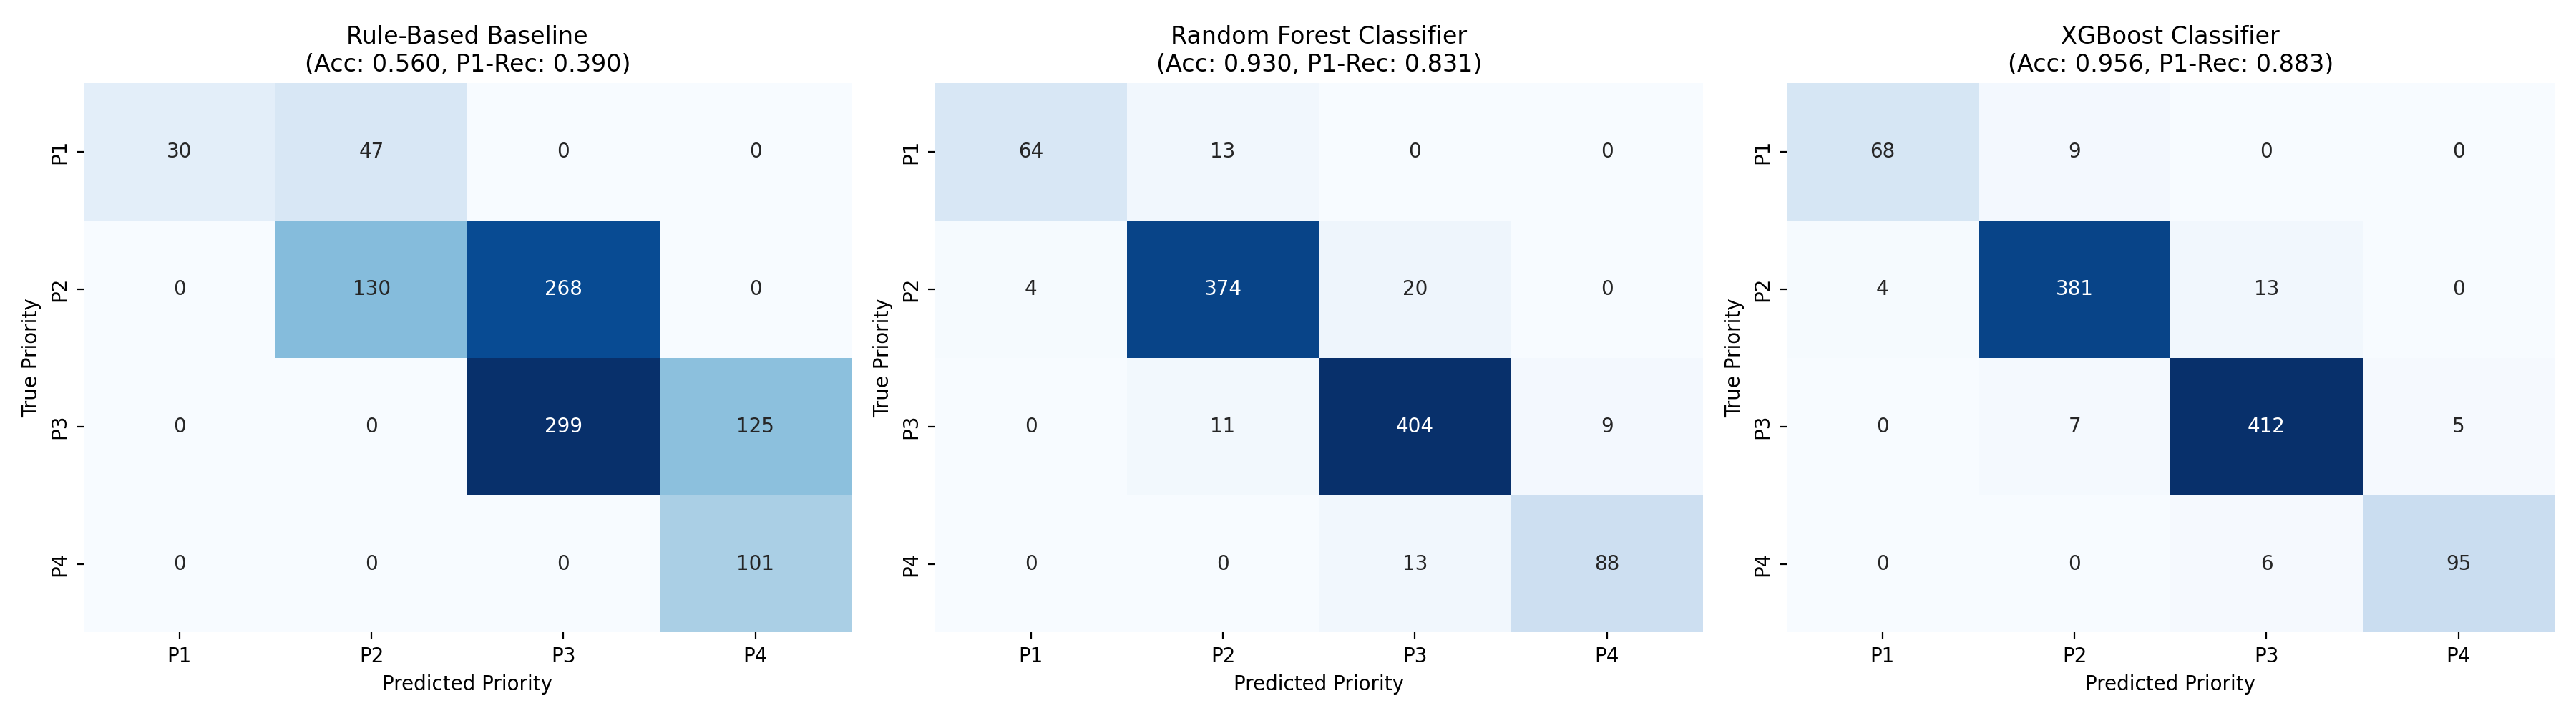

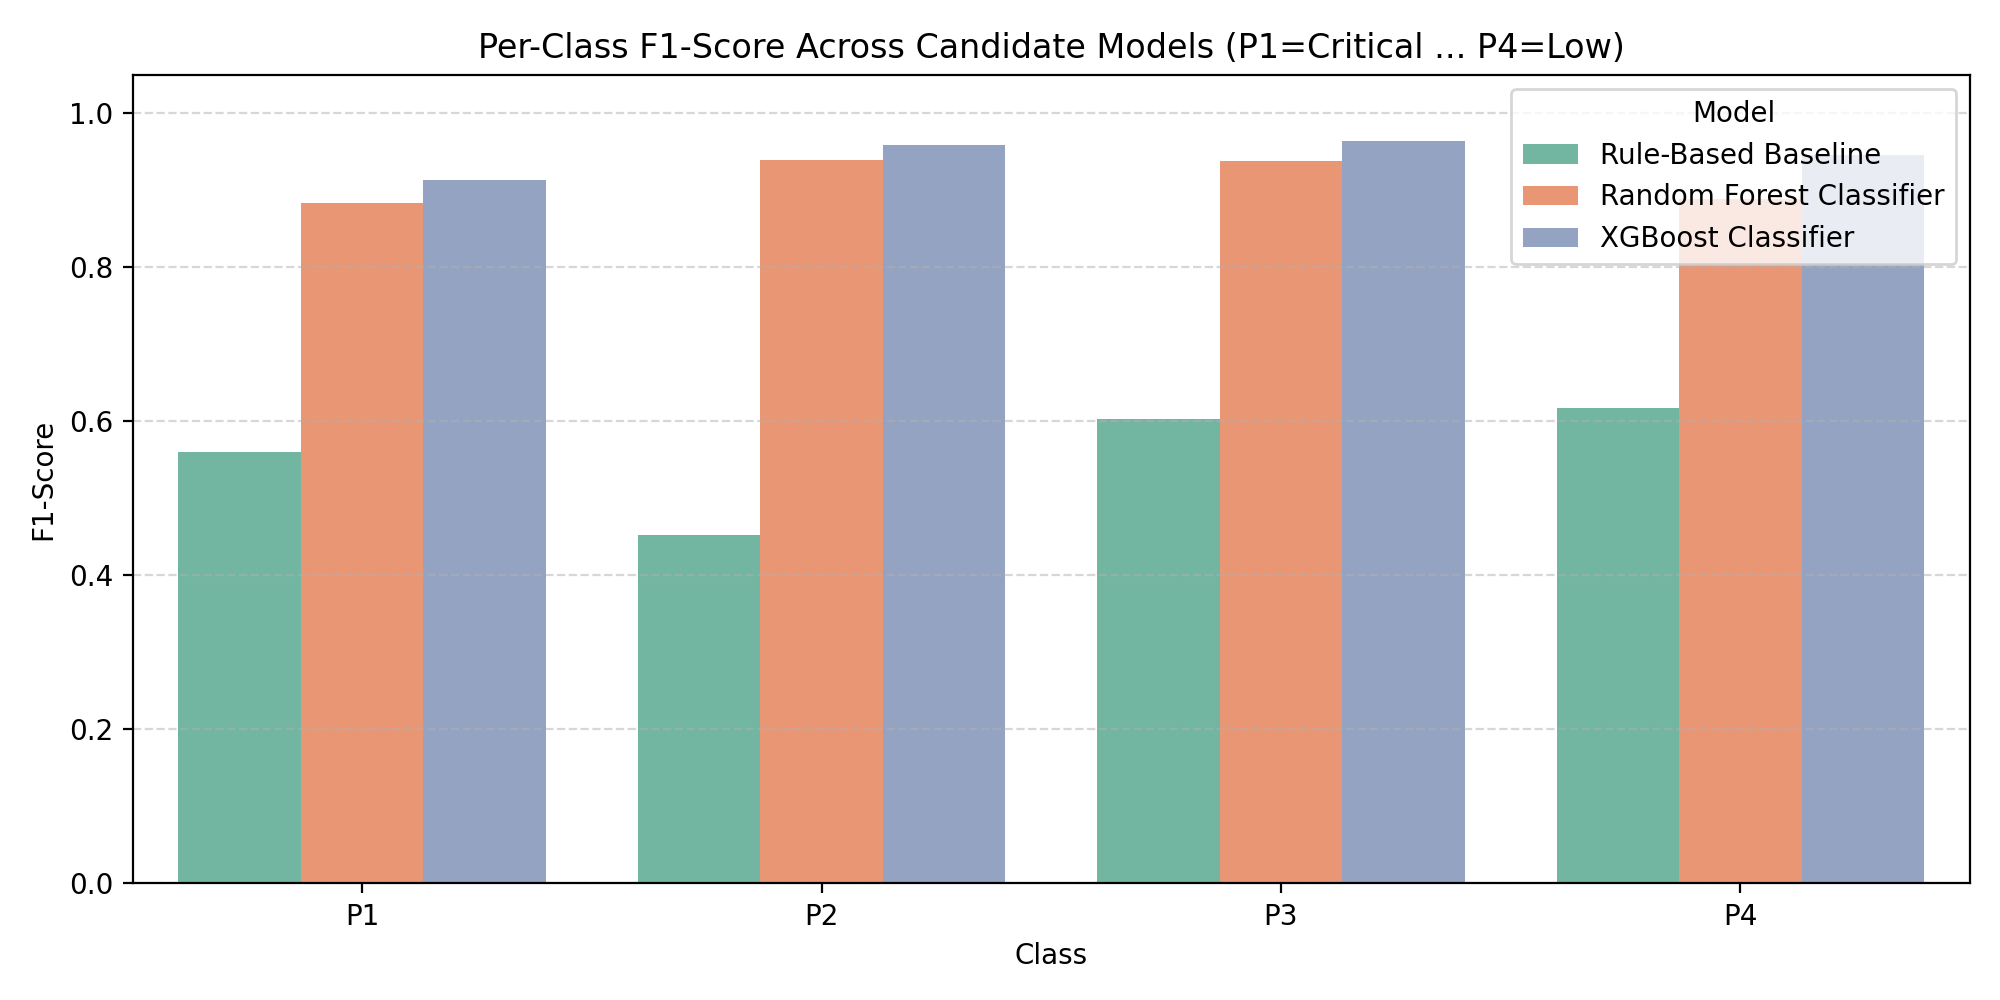

In [4]:
from IPython.display import Image, display

cm_path = eval_results["cm_path"]
if cm_path.exists():
    display(Image(filename=str(cm_path)))

f1_path = eval_results["f1_path"]
if f1_path.exists():
    display(Image(filename=str(f1_path)))
